In [1]:
# Find the repo root (the folder containing src/paths.py), put src/ on the import
# path, and run from the repo root so relative data/ and calibration/ paths resolve.
import os, sys
_root = os.path.abspath(os.getcwd())
while not os.path.exists(os.path.join(_root, "src", "paths.py")):
    _parent = os.path.dirname(_root)
    if _parent == _root:
        raise RuntimeError("Could not find src/paths.py above the working directory")
    _root = _parent
if os.path.join(_root, "src") not in sys.path:
    sys.path.insert(0, os.path.join(_root, "src"))
os.chdir(_root)

In [2]:
%load_ext autoreload
%autoreload 2

from plotting import *
from optimization_utils import smooth_inflow
from param_loader import METANET_Params

In [4]:
path_id = "i24/i24_11_30"
data_path = f"data/{path_id}"
lanes = np.load(f"{data_path}/lane_mapping.npy")
i24_rho = np.load(f"{data_path}/rho_hat.npy") / lanes
i24_q = np.load(f"{data_path}/q_hat.npy")

T = 10/3600
l = 0.4
num_calibrated_segments = 14
downstream_density = smooth_inflow(i24_rho[:, -1])
data_inflow = smooth_inflow(i24_q[:, 0])

i24_rho = np.where(i24_rho == 0.0, 1e-3, i24_rho)
i24_q = np.where(i24_q == 0.0, 1e-3, i24_q)
i24_v = i24_q/(i24_rho * lanes)
init_traffic_state = (i24_rho[0, 1:-1], i24_v[0, 1:-1], data_inflow[0], 0)

## Plotting robustness curves

8
{6: '#4F8FCF', 12: '#002DF4', 30: '#5644FA', 60: '#8B59FF', 90: '#BB4EFF', 120: '#E45DFF', 180: '#FF5DBE', 360: '#FF5D5D'}


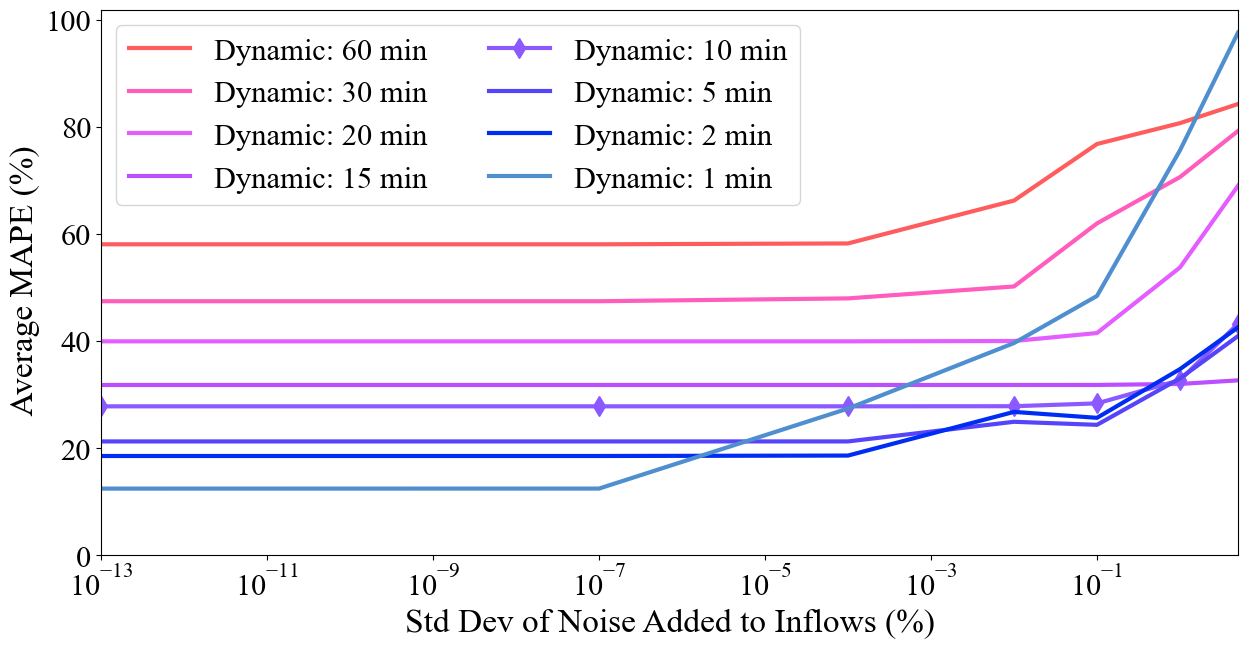

In [6]:
# root_dir = "cdc2026/synthetic_data_rain/mpc_calibration_results_var0.2"
root_dir = f"calibration/{path_id}" + "/calibration_dynamic_smooth" #"calibration/i24/i24_11_30/calibration_dynamic_smooth"
ch = [360, 180, 120, 90, 60, 30, 12, 6]
dir_to_plot = [f"{root_dir}/control_h_{c}" for c in ch] #["calibration/i24/i24_11_30/calibration_static/fixed_ramping"] + 
print(len(dir_to_plot))

plot_percentile_curves(dir_to_plot, desired_legend_order=[f"Dynamic: {int(c/6)} min" for c in ch], 
                       metric="mean", percentile=False, save_path=f"{root_dir}/figs", figname = "performance_plot.pdf", highlight_hor=[60])

{6: '#4F8FCF', 12: '#002DF4', 30: '#5644FA', 60: '#8B59FF', 90: '#BB4EFF', 120: '#E45DFF', 180: '#FF5DBE', 360: '#FF5D5D'}


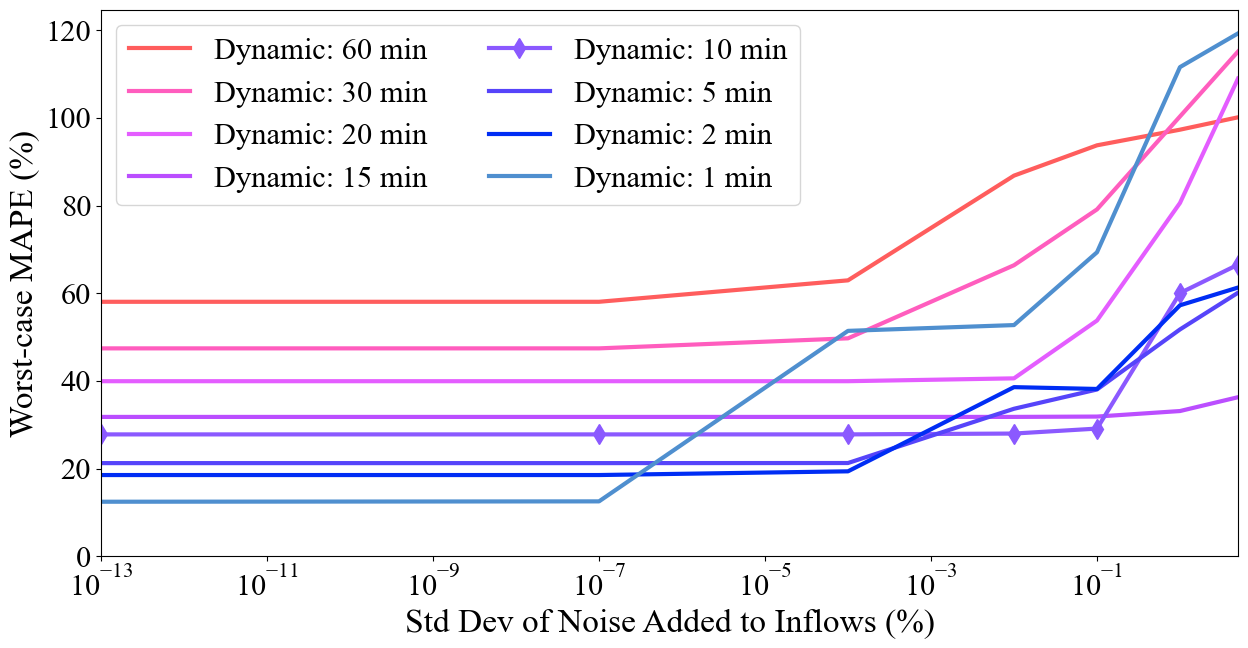

In [7]:
# # root_dir = "cdc2026/synthetic_data_rain/mpc_calibration_results_var0.2"
# root_dir = "calibration/i24/i24_11_30/calibration_dynamic_smooth"
# ch = [180, 120, 90, 60, 30, 12, 6]
# dir_to_plot = ["calibration/i24/i24_11_30/calibration_static/fixed_ramping"] + [f"{root_dir}/control_h_{c}" for c in ch]
# print(len(dir_to_plot))

plot_percentile_curves(dir_to_plot, desired_legend_order=[f"Dynamic: {int(c/6)} min" for c in ch], 
                       metric="max", percentile=False, save_path=f"{root_dir}/figs", 
                       figname = "performance_plot_worstcase.pdf", highlight_hor=[60])

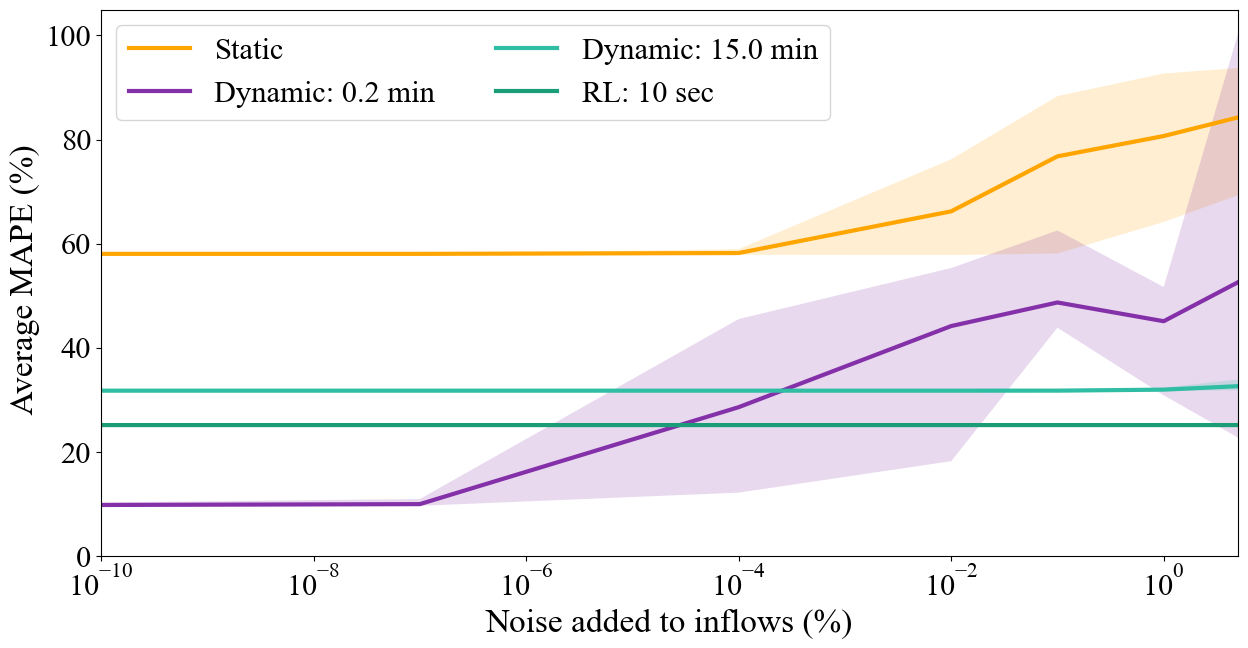

In [9]:
dir_to_plot = [f"calibration/{path_id}/calibration_static/fixed_ramping", 
               f"calibration/{path_id}/calibration_dynamic_smooth/control_h_1", 
               f"calibration/{path_id}/calibration_dynamic_smooth/control_h_90",  
               f"calibration/{path_id}/rl_calibration"]

plot_percentile_curves(dir_to_plot, desired_legend_order=["Static", "Dynamic: 0.2 min", "Dynamic: 15.0 min", "RL: 10 sec"], 
                       metric="mean", g_fontsize=24, percentile=True, horizon_decimals=1)

## Plotting perturbation curves

In [4]:
from eval_metrics import mape
from simulation_utils import run_metanet_sim


Config: OCP (itsc_final/calibration_results/OCP)
Segment: 0
Cache:  smooth_landscape_plots/perturbation_cache/OCP_seg0_bc0_n201_pmin-0.1000_pmax0.1000.npz
  Loading existing perturbation data...

Config: MPC_90 (itsc_final/smooth_mpc_calibration_results/)
Segment: 0
Cache:  smooth_landscape_plots/perturbation_cache/MPC_90_seg0_bc0_n201_pmin-0.1000_pmax0.1000.npz
  Loading existing perturbation data...

Config: RL (calibration_results/i24_11_30_rl_posttrain_2/)
Segment: 0
Cache:  smooth_landscape_plots/perturbation_cache/RL_seg0_bc0_n201_pmin-0.1000_pmax0.1000.npz
  Loading existing perturbation data...


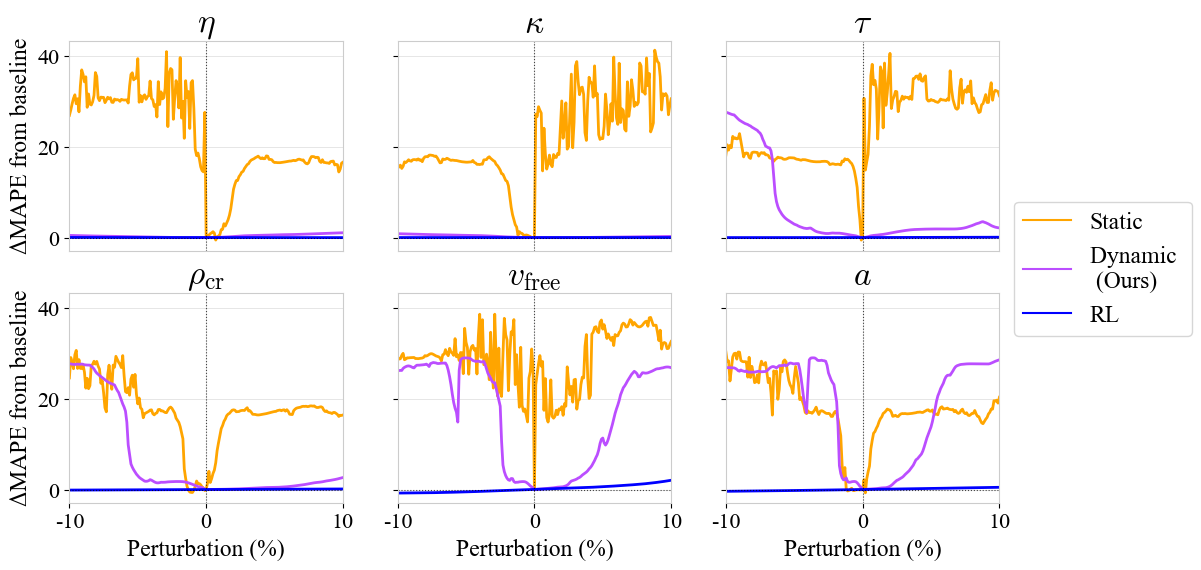


Saved plot to smooth_landscape_plots/sensitivity_comparison_rl_segment0.pdf


<Figure size 640x480 with 0 Axes>

In [ ]:
# Each config specifies its own lanes and preprocessing, matching standalone cells

seg = 0
param_configs = [
    {
        "label": "OCP",
        "results_dir": f"calibration/{path_id}/calibration_static/fixed_ramping",
        "control_hor": None,
        "lanes": lanes[1:-1],
        "smooth_rho": False,
        "smooth_bc": True,
        "segment_idx": seg,      # optional, defaults to 7
        "bc_timestep": 0,    # optional, defaults to 180
        "rho_hat": i24_rho,
        "q_hat": i24_q,
    },
    {
        "label": "MPC_90",
        "results_dir": f"calibration/{path_id}/calibration_dynamic_smooth/",
        "control_hor": 90,
        "lanes": lanes[1:-1],
        "smooth_rho": False,
        "smooth_bc": True,
        "segment_idx": seg,      # optional, defaults to 7
        "bc_timestep": 0,    # optional, defaults to 180
        "rho_hat": i24_rho,
        "q_hat": i24_q,
    },
    {
        "label": "RL",
        "results_dir": f"calibration/{path_id}/rl_calibration/",
        "control_hor": None,
        "lanes": lanes[1:-1],
        "smooth_rho": False,
        "smooth_bc": True,
        "segment_idx": seg,      # optional, defaults to 7
        "bc_timestep": 0,    # optional, defaults to 180
        "rho_hat": i24_rho,
        "q_hat": i24_q,
    }
]

all_results = run_and_plot_perturbations(
    param_configs=param_configs,
    T=T, l=l,
    num_calibrated_segments=num_calibrated_segments,
    run_metanet_sim=run_metanet_sim,
    mape_fn=mape,
    save_path=f"figs/itsc2026/smooth_landscape_plots/sensitivity_comparison_rl_segment{seg}.pdf",
    cache_dir="figs/itsc2026/smooth_landscape_plots/perturbation_cache",
    use_cache=True,
    load_only=False,
    g_fontsize=16,
)


## MPC Horizon comparison

## Time-space diagrams from noisy inflows

In [8]:
from eval_metrics import generate_perturbations

In [15]:
# Change these values to correspond to the appropriate paths / data
root_dir = f"calibration/{path_id}" + "/calibration_dynamic_smooth"
ga_root_dir = f"calibration/{path_id}" + "/ga_calibration/"
horizons = [360]
params = [METANET_Params(path=root_dir, num_segments=num_calibrated_segments, 
                         num_timesteps=len(downstream_density),
                         control_h=H).get_params() for H in horizons] +\
        [METANET_Params(path=ga_root_dir).get_params()]
        # [METANET_Params(path=f"calibration/{path_id}/calibration_dynamic_smooth", num_segments=num_calibrated_segments, num_timesteps=len(downstream_density), control_h=90).get_params()]+\
        # [METANET_Params(path=f"calibration/{path_id}/rl_calibration", num_segments=num_calibrated_segments).get_params()]
labels = ["Gradient-based \n(IPOPT)", "Gradient-free \n(GA)"]#, "Gradient-based \n(MPC) transfer", "Gradient-free \n(RL) transfer"]#["Static", "Dynamic \n(15 min)"]
percent_noise_list = [0.01, 1]  # or whatever you want

In [16]:
data = {labels[i]: dict() for i in range(len(labels))}

for i in range(len(params)):
    param = params[i]
    rho_sim, v_sim, _, tts_sim = run_metanet_sim(
        T, 
        l, 
        init_traffic_state,
        data_inflow,
        downstream_density,
        param,
        vsl_speeds=None,
        lanes={i: lanes[1:-1][i] for i in range(num_calibrated_segments)},
        plotting=True,
        real_data=True
    )
    data[labels[i]]["v_sim"] = v_sim

In [17]:
# Dicts to hold results for each noise level

for k in range(len(params)):
    param = params[k]
    label = labels[k]

    for percent_noise in percent_noise_list:
        plotting_v_sim = None
        plotting_rho_sim = None
        worst_v_sim = None

        perturbs = generate_perturbations(data_inflow, percent_noise, num=50)
        for perturbed_conditions in perturbs:
            rho_sim_noise, v_sim_noise, _, tts_noise = run_metanet_sim(T,
                                        l,
                                        init_traffic_state,
                                        perturbed_conditions,
                                        downstream_density,
                                        param, 
                                        vsl_speeds=None,
                                        lanes={i: lanes[1:-1][i] for i in range(num_calibrated_segments)},
                                        plotting=True,
                                        real_data=True)
        
            error = mape(i24_v[:, 1:-1], v_sim_noise[0:-1, :])

            if worst_v_sim is None or error > worst_v_sim:
                plotting_v_sim = v_sim_noise
                plotting_rho_sim = rho_sim_noise
                worst_v_sim = error

        # Store outputs
        print(worst_v_sim)
        data[label][f"v_sim_noise_{percent_noise}"] = plotting_v_sim

79.29058787136535
96.02949515983676
103.55718714151307
103.56963012022437


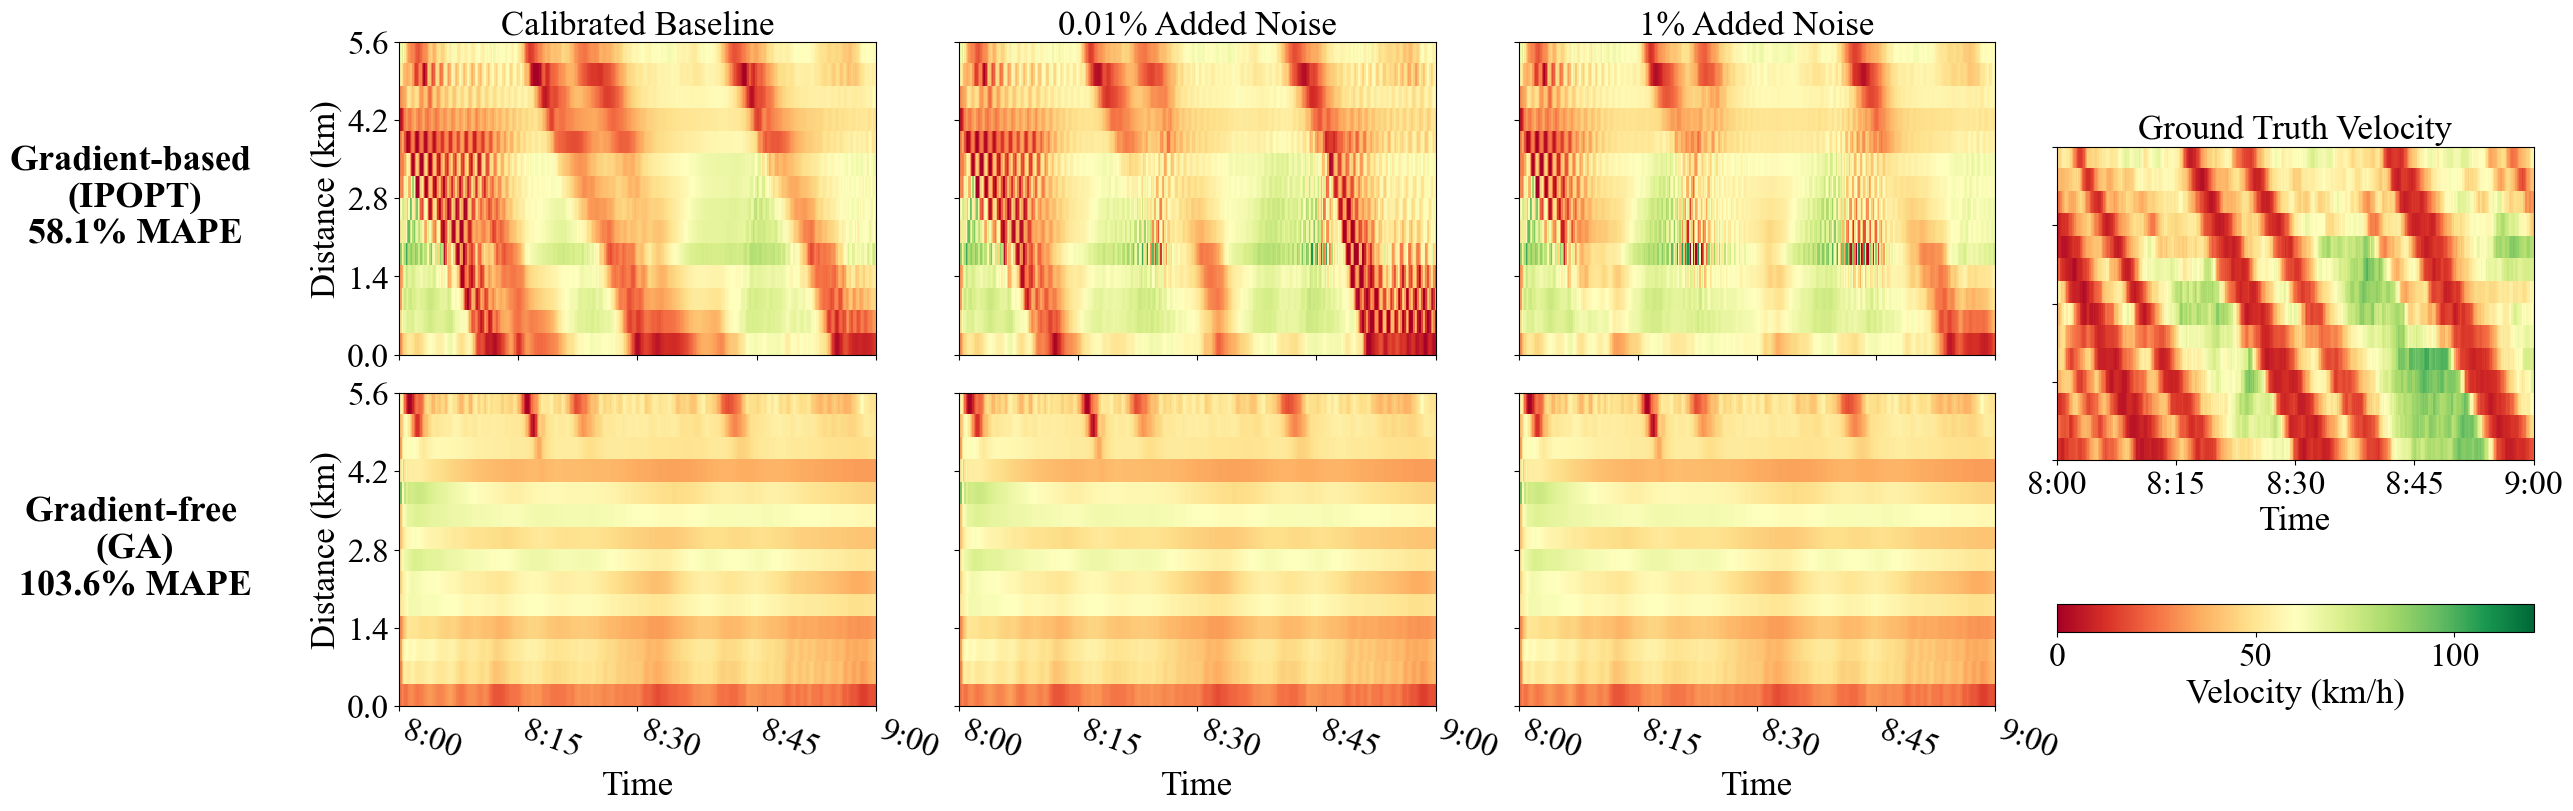

In [18]:
plot_time_space_grid(
    data=data,
    labels=labels,
    percent_noise_list=percent_noise_list,
    v_hat=i24_v,
    figsize_per_row=4,
    figsize_per_col=4.0,
    value_key_base="v_sim",
    vmin=0,
    vmax=120,
    cmap="RdYlGn",
    g_fontsize=24,
    colorbar_label="Velocity (km/h)",
    clean_title="Calibrated Baseline",
    vhat_title="Ground Truth Velocity",
    save_path="figs/itsc2026/GA_vs_IPOPT_comparison.png",
    show_gt=True
)

## Fundamental diagram comparison

In [110]:
scenario = {
    "T": T,
    "l": l,
    "lanes": lanes[1:-1],
    "num_calibrated_segments": num_calibrated_segments,
    "rho_hat": i24_rho,
    "q_hat": i24_q,
    "init_traffic_state": init_traffic_state,
    "downstream_density": downstream_density,
    "data_inflow": data_inflow,
}

IsADirectoryError: [Errno 21] Is a directory: 'itsc_final/figs/static_fd.png'

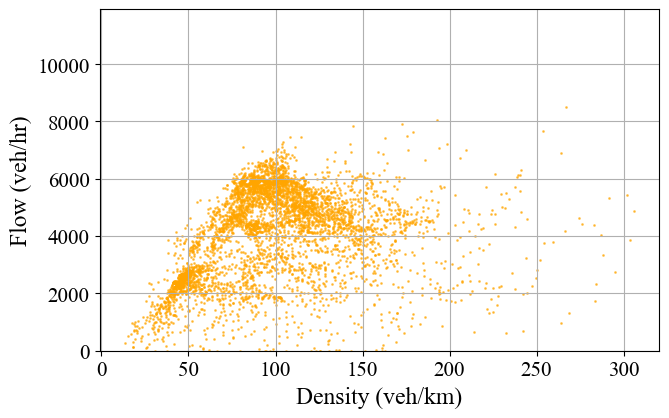

In [113]:
plot_fd_diagrams([METANET_Params(f"calibration/{path_id}/calibration_static/fixed_ramping").get_params()],
                  # METANET_Params(f"calibration/{path_id}/ga_calibration/trials2500").get_params(),
                  # METANET_Params(f"calibration/{path_id}/calibration_dynamic_smooth", control_h=90, num_timesteps=360).get_params()], 
                #   METANET_Params(f"calibration/{path_id}/rl_calibration").get_params()],
                 scenario_info=scenario,
                 labels=["Static (Gradient-based)"],#,  "Static (Gradient-free: GA)", "Dynamic (Gradient-based)"],
                 show_gt=False,
                 show_legend=False,
                 save_path="figs/itsc2026/static_fd.png") # "RL (10 sec)"])